# Scientific Evaluation — Controlled Agentic XAI-RAG

**System:** HMS live prediction (CatBoost + TreeSHAP) → case formatter → LLM query planning → hybrid retrieval (FAISS + BM25) → report generation.

This notebook produces **publication-ready tables and figures** for the Results section of a scientific paper.

| Section | Metrics |
|---------|--------|
| 1. Knowledge base | Corpus size, document/chunk distribution |
| 2. Predictive layer | CatBoost AUC, F1, calibration (Phase 1) |
| 3. Retrieval | P@5, R@5, R@10, MRR, nDCG@10 — BM25 vs hybrid |
| 4. Query planning | Report-question count, XAI factor coverage, slot coverage |
| 5. Report quality | Schema validity, safety, XAI alignment, question coverage, citations |
| 6. Summary | Master results table + LaTeX export |

**Outputs:** `figures/paper/` and `paper_outputs/evaluation/`

## Configuration

Set `RUN_RETRIEVAL_EVAL=True` to benchmark BM25 vs hybrid (first hybrid run may build FAISS index — allow several minutes). Set `RUN_PIPELINE=False` unless you want fresh end-to-end runs on all preset cases.

In [1]:
import json
import math
import re
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

try:
    import seaborn as sns
    sns.set_theme(style="whitegrid", context="talk", font_scale=0.85)
except ImportError:
    sns = None

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 200, "figure.figsize": (10, 6)})

NOTEBOOK_DIR = Path.cwd()
ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
SRC = ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

FIG_DIR = ROOT / "figures" / "paper"
OUT_DIR = ROOT / "paper_outputs" / "evaluation"
FIG_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

RUN_RETRIEVAL_EVAL = True
RETRIEVAL_LIMIT = 100
RUN_PIPELINE = False
K_RETRIEVAL = 10

METRIC_COLS = ["precision@5", "recall@5", "recall@10", "hit@5", "hit@10", "mrr", "ndcg@10"]
retrieval_detail = pd.DataFrame()
retrieval_summary_flat = pd.DataFrame()
qp_df = pd.DataFrame()
report_df = pd.DataFrame()
bench = pd.DataFrame()
pred_metrics: dict = {}

def savefig(name: str):
    path = FIG_DIR / name
    plt.savefig(path, bbox_inches="tight")
    print(f"Saved: {path}")

from controlled_agentic_xai_rag.config_loader import load_config, path as cfg_path, cfg_get
from controlled_agentic_xai_rag.evaluation.metrics import mrr, ndcg_at_k, precision_at_k, recall_at_k
from controlled_agentic_xai_rag.schemas import validate
from controlled_agentic_xai_rag.evaluation.benchmark_gold import PRESET_CASE_IDS
from controlled_agentic_xai_rag.evaluation.eval_report_batch import pass_rates_with_n
from controlled_agentic_xai_rag.validators.safety_rules import check_safety_rules, report_text
from controlled_agentic_xai_rag.validators.xai_alignment import check_xai_alignment

load_config.cache_clear()
print(f"Project root: {ROOT}")

Project root: c:\Users\MossabBatal\Desktop\psychology_mas\controlled_agentic_xai_rag


---
## Figure 0 — System architecture (Methods figure)

Saved: c:\Users\MossabBatal\Desktop\psychology_mas\controlled_agentic_xai_rag\figures\paper\fig0_pipeline_architecture.png


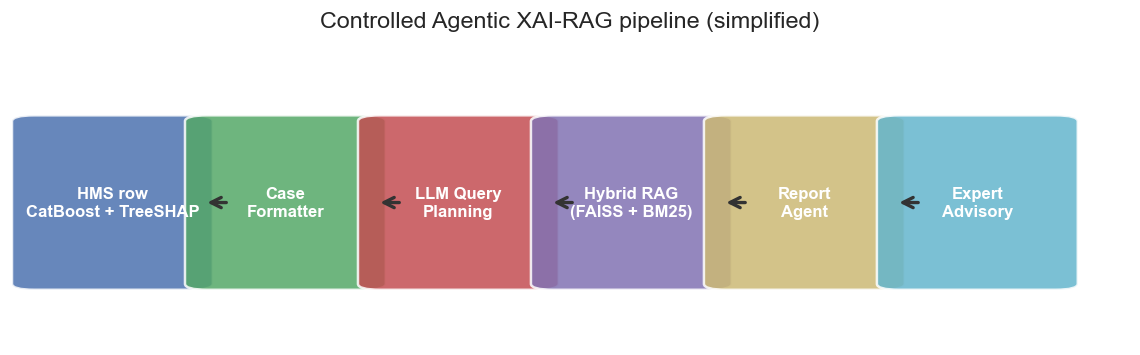

In [2]:
fig, ax = plt.subplots(figsize=(12, 3.2))
ax.axis("off")
steps = [
    "HMS row\nCatBoost + TreeSHAP",
    "Case\nFormatter",
    "LLM Query\nPlanning",
    "Hybrid RAG\n(FAISS + BM25)",
    "Report\nAgent",
    "Expert\nAdvisory",
]
colors = ["#4C72B0", "#55A868", "#C44E52", "#8172B3", "#CCB974", "#64B5CD"]
x0, w, h = 0.02, 0.14, 0.55
for i, (label, col) in enumerate(zip(steps, colors)):
    x = x0 + i * 0.155
    rect = mpatches.FancyBboxPatch((x, 0.2), w, h, boxstyle="round,pad=0.02", fc=col, ec="white", alpha=0.85)
    ax.add_patch(rect)
    ax.text(x + w / 2, 0.475, label, ha="center", va="center", fontsize=10, color="white", fontweight="bold")
    if i < len(steps) - 1:
        ax.annotate("", xy=(x + w + 0.012, 0.475), xytext=(x + w + 0.035, 0.475),
                    arrowprops=dict(arrowstyle="->", lw=2, color="#333333"))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_title("Controlled Agentic XAI-RAG pipeline (simplified)", fontsize=14, pad=12)
savefig("fig0_pipeline_architecture.png")
plt.show()

---
## 1. Knowledge base statistics

,n_documents,n_chunks,mean_chunks_per_doc,mean_chunk_chars
0,44,5740,130.5,854


Saved: c:\Users\MossabBatal\Desktop\psychology_mas\controlled_agentic_xai_rag\figures\paper\fig1_corpus_expertise_areas.png


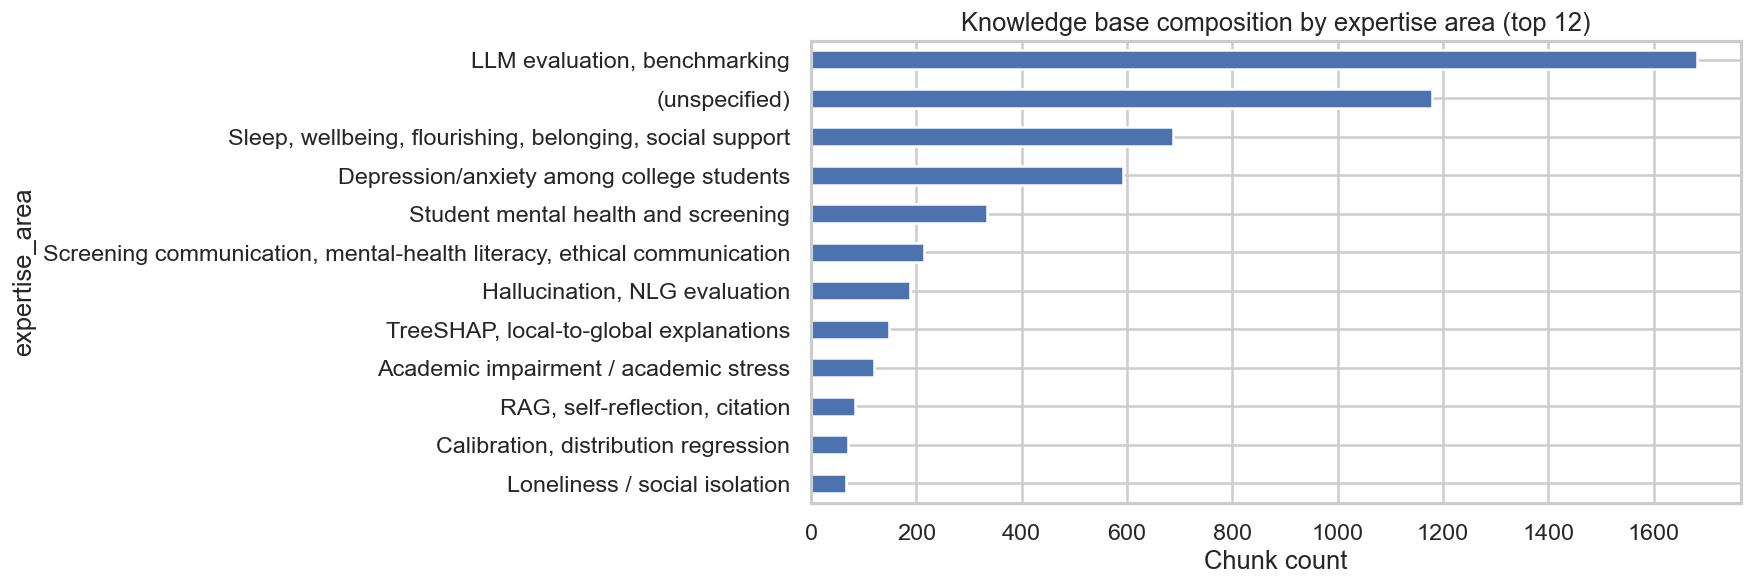

In [3]:
chunks = pd.read_csv(cfg_path("processed_chunks_csv"))
meta = pd.read_csv(cfg_path("corpus_metadata_csv"))

kb_stats = {
    "n_documents": meta["doc_id"].nunique(),
    "n_chunks": len(chunks),
    "mean_chunks_per_doc": round(len(chunks) / max(meta["doc_id"].nunique(), 1), 1),
    "mean_chunk_chars": int(chunks["text"].str.len().mean()),
}
kb_df = pd.DataFrame([kb_stats])
display(kb_df)
kb_df.to_csv(OUT_DIR / "table1_knowledge_base.csv", index=False)

area_counts = (
    meta.assign(expertise_area=meta["expertise_area"].fillna("(unspecified)"))
    .groupby("expertise_area")["chunk_count"].sum()
    .sort_values(ascending=False)
    .head(12)
)

fig, ax = plt.subplots(figsize=(10, 5))
area_counts.plot(kind="barh", ax=ax, color="#4C72B0")
ax.set_xlabel("Chunk count")
ax.set_title("Knowledge base composition by expertise area (top 12)")
ax.invert_yaxis()
savefig("fig1_corpus_expertise_areas.png")
plt.show()

---
## 2. Predictive layer (CatBoost + TreeSHAP)

Loads Phase 1 performance card when available; otherwise computes hold-out metrics on the HMS test split.

,source,model,auc,accuracy,f1,brier,pr_auc
0,phase1_artifact,CatBoost,0.852,0.7718,0.7524,0.1569,0.8248


Saved: c:\Users\MossabBatal\Desktop\psychology_mas\controlled_agentic_xai_rag\figures\paper\fig2_catboost_performance.png


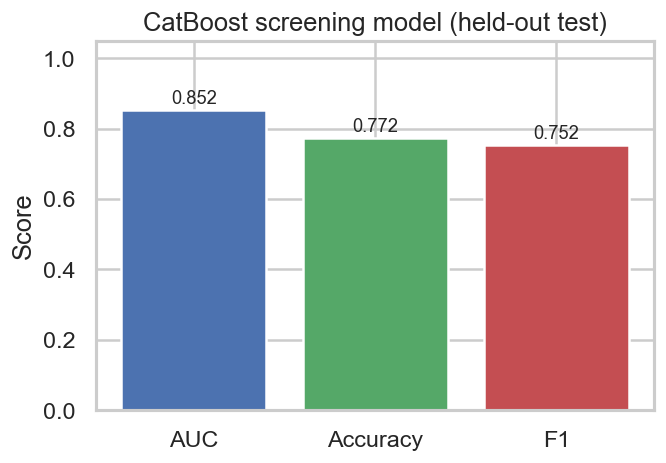

In [ ]:
phase1 = Path(cfg_get("paths", "phase1_root", default=str(ROOT.parent / "xai_rag_depression")))
catboost_perf_path = phase1 / "outputs" / "cards" / "perf_CatBoost.json"
model_perf_csv = phase1 / "outputs" / "model_performance.csv"

pred_metrics: dict = {}
if catboost_perf_path.exists():
    perf_cat = json.loads(catboost_perf_path.read_text(encoding="utf-8"))
    m = perf_cat.get("metrics", perf_cat)
    pred_metrics = {
        "source": "phase1_artifact",
        "model": "CatBoost",
        "auc": m.get("auc", np.nan),
        "accuracy": m.get("accuracy", np.nan),
        "f1": m.get("f1", np.nan),
        "brier": m.get("brier", np.nan),
        "pr_auc": m.get("pr_auc", np.nan),
    }
elif model_perf_csv.exists():
    row = pd.read_csv(model_perf_csv).query("model == 'CatBoost'").iloc[0]
    pred_metrics = {
        "source": "phase1_model_performance_csv",
        "model": "CatBoost",
        "auc": row["auc"],
        "accuracy": row["accuracy"],
        "f1": row["f1"],
        "brier": row["brier"],
        "pr_auc": row.get("pr_auc", np.nan),
    }
else:
    try:
        from controlled_agentic_xai_rag.prediction.hms_predictor import get_test_set_size

        pred_metrics = {
            "source": "live_prediction_available",
            "model": "CatBoost",
            "n_test_rows": get_test_set_size(),
            "note": "Run Phase 1 (xai_rag_depression) to export AUC/F1 tables.",
        }
    except Exception as exc:
        pred_metrics = {"source": "unavailable", "error": str(exc)}

pred_df = pd.DataFrame([pred_metrics])
display(pred_df.round(4) if "auc" in pred_metrics else pred_df)
pred_df.to_csv(OUT_DIR / "table2_prediction_metrics.csv", index=False)

if pred_metrics.get("auc") is not None and not (isinstance(pred_metrics.get("auc"), float) and np.isnan(pred_metrics["auc"])):
    fig, ax = plt.subplots(figsize=(6, 4))
    names = ["AUC", "Accuracy", "F1"]
    vals = [pred_metrics["auc"], pred_metrics["accuracy"], pred_metrics["f1"]]
    ax.bar(names, vals, color=["#4C72B0", "#55A868", "#C44E52"])
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("Score")
    ax.set_title("CatBoost screening model (held-out test)")
    for i, v in enumerate(vals):
        ax.text(i, v + 0.02, f"{v:.3f}", ha="center", fontsize=11)
    savefig("fig2_catboost_performance.png")
    plt.show()

In [5]:
if "METRIC_COLS" not in globals():
    METRIC_COLS = ["precision@5", "recall@5", "recall@10", "hit@5", "hit@10", "mrr", "ndcg@10"]


---
## 3. Retrieval evaluation (100-question benchmark)

Compares **BM25-only** vs **hybrid FAISS+BM25 (RRF)** on `rag_benchmark_100_questions.csv`.

Gold relevance uses **relaxed matching**: exact chunk ID when present in corpus, otherwise any chunk sharing the same document prefix (`DOC_*` before `_p`). This handles corpus ID re-indexing between Phase 2 and the current build.

In [ ]:
from controlled_agentic_xai_rag.evaluation.benchmark_gold import resolve_gold_chunks, load_corpus_metadata



def eval_retriever_on_benchmark(retriever, bench: pd.DataFrame, chunks_df: pd.DataFrame, meta: pd.DataFrame, k: int = 10) -> pd.DataFrame:
    rows = []
    for _, row in bench.iterrows():
        q = str(row.get("question", "")).strip()
        relevant = resolve_gold_chunks(row, chunks_df, meta)
        if not q or not relevant:
            continue
        hits = retriever.retrieve(q, k=k)
        retrieved = [h.chunk_id for h in hits]
        rows.append({
            "question_id": row.get("question_id", ""),
            "category": row.get("category", ""),
            "difficulty": row.get("difficulty", ""),
            "answer_type": row.get("answer_type_master", row.get("answer_type", "")),
            "retriever": retriever.name,
            "n_gold": len(relevant),
            "precision@5": precision_at_k(relevant, retrieved, 5),
            "recall@5": recall_at_k(relevant, retrieved, 5),
            "recall@10": recall_at_k(relevant, retrieved, 10),
            "hit@5": float(any(c in relevant for c in retrieved[:5])),
            "hit@10": float(any(c in relevant for c in retrieved[:10])),
            "mrr": mrr(relevant, retrieved),
            "ndcg@10": ndcg_at_k(relevant, retrieved, 10),
        })
    return pd.DataFrame(rows)


bench_path = cfg_path("benchmarks_dir") / "rag_benchmark_100_questions.csv"
bench = pd.read_csv(bench_path).head(RETRIEVAL_LIMIT)
meta = load_corpus_metadata()

retrieval_detail = pd.DataFrame()
if RUN_RETRIEVAL_EVAL:
    from controlled_agentic_xai_rag.retrieval.hybrid_rrf import get_retriever

    parts = []
    for bm25_only in (True, False):
        print(f"Evaluating retriever: {'BM25' if bm25_only else 'Hybrid FAISS+BM25'}…")
        r = get_retriever(bm25_only=bm25_only)
        parts.append(eval_retriever_on_benchmark(r, bench, chunks, meta, k=K_RETRIEVAL))
    retrieval_detail = pd.concat(parts, ignore_index=True)
    retrieval_detail.to_csv(OUT_DIR / "retrieval_per_question.csv", index=False)
    print(f"Retrieval benchmark: {len(retrieval_detail)} questions with resolvable gold (target {RETRIEVAL_LIMIT}).")
else:
    cached = OUT_DIR / "retrieval_per_question.csv"
    if cached.exists():
        retrieval_detail = pd.read_csv(cached)
        print("Loaded cached retrieval results.")

if not retrieval_detail.empty:
    retrieval_summary = (
        retrieval_detail.groupby("retriever")[METRIC_COLS]
        .agg(["mean", "std"])
        .round(4)
    )
    retrieval_summary_flat = retrieval_detail.groupby("retriever")[METRIC_COLS].mean().round(4).reset_index()
    display(retrieval_summary_flat)
    retrieval_summary_flat.to_csv(OUT_DIR / "table3_retrieval_summary.csv", index=False)
else:
    print("No retrieval evaluation results.")

Evaluating retriever: BM25…
Evaluating retriever: Hybrid FAISS+BM25…


KeyboardInterrupt: 

: 

Saved: c:\Users\MossabBatal\Desktop\psychology_mas\controlled_agentic_xai_rag\figures\paper\fig3_retrieval_comparison.png


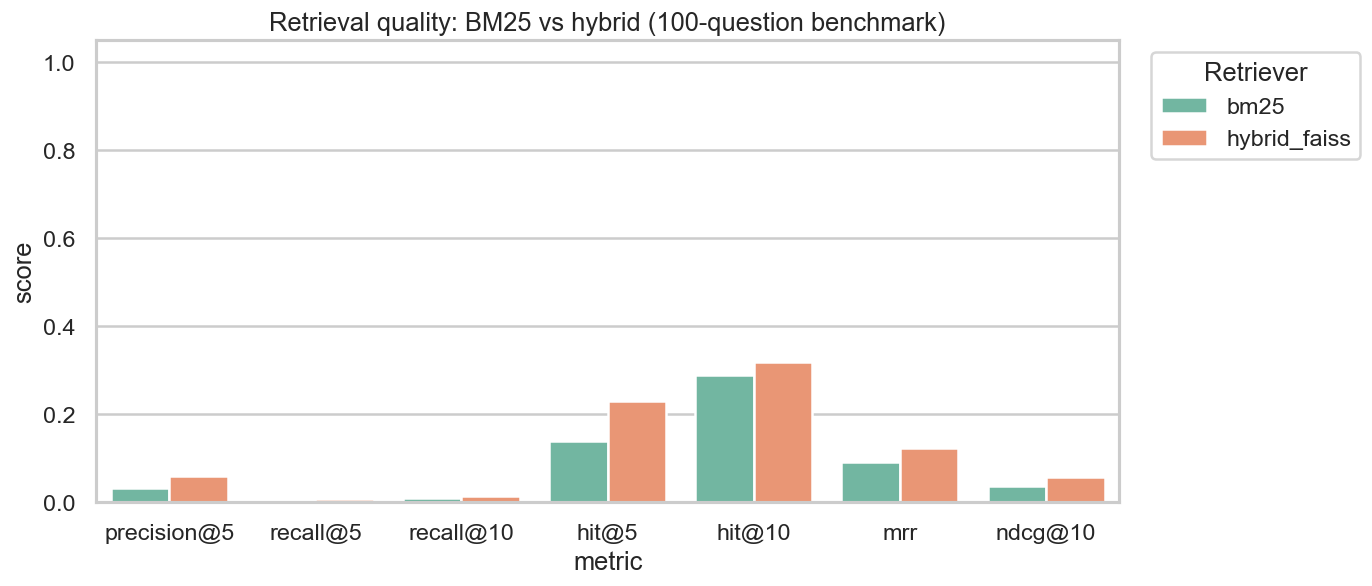

Saved: c:\Users\MossabBatal\Desktop\psychology_mas\controlled_agentic_xai_rag\figures\paper\fig4_retrieval_hit10_by_category.png


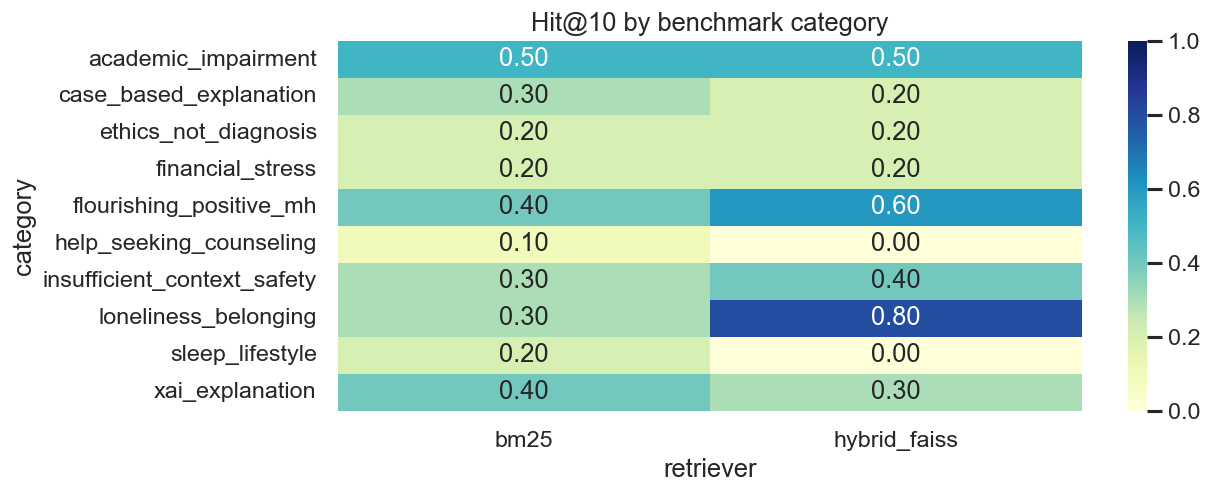

Saved: c:\Users\MossabBatal\Desktop\psychology_mas\controlled_agentic_xai_rag\figures\paper\fig5_retrieval_ndcg_by_difficulty.png


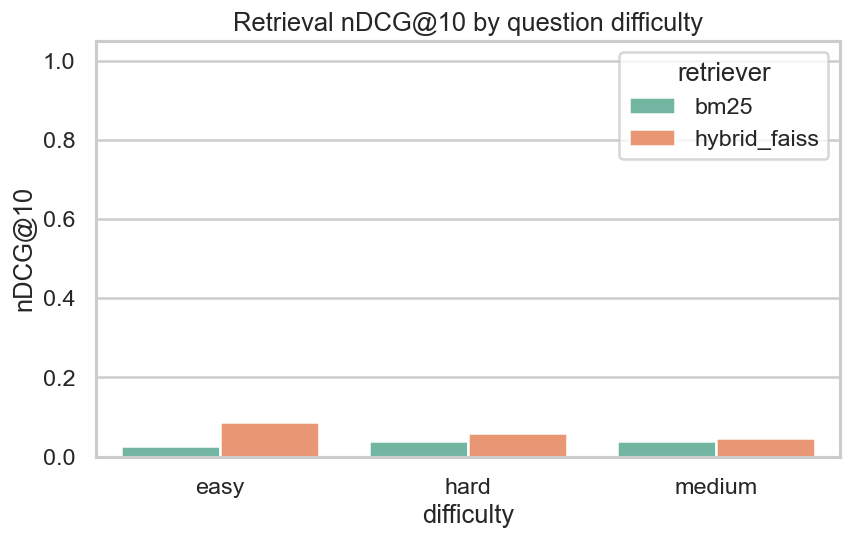

In [ ]:
if not retrieval_detail.empty:
    # Fig 3 — overall retriever comparison
    plot_df = retrieval_detail.groupby("retriever")[METRIC_COLS].mean().reset_index()
    melt = plot_df.melt(id_vars="retriever", var_name="metric", value_name="score")
    fig, ax = plt.subplots(figsize=(11, 5))
    if sns is not None:
        sns.barplot(data=melt, x="metric", y="score", hue="retriever", ax=ax, palette="Set2")
    else:
        x = np.arange(len(METRIC_COLS))
        w = 0.35
        for i, ret in enumerate(plot_df["retriever"]):
            ax.bar(x + (i - 0.5) * w, plot_df.loc[plot_df["retriever"] == ret, METRIC_COLS].values[0], width=w, label=ret)
        ax.set_xticks(x)
        ax.set_xticklabels(METRIC_COLS, rotation=30, ha="right")
    ax.set_ylim(0, 1.05)
    ax.set_title("Retrieval quality: BM25 vs hybrid (100-question benchmark)")
    ax.legend(title="Retriever", bbox_to_anchor=(1.02, 1), loc="upper left")
    savefig("fig3_retrieval_comparison.png")
    plt.show()

    # Fig 4 — heatmap by category (hit@10)
    cat_pivot = retrieval_detail.pivot_table(index="category", columns="retriever", values="hit@10", aggfunc="mean")
    fig, ax = plt.subplots(figsize=(10, max(4, 0.35 * len(cat_pivot))))
    if sns is not None:
        sns.heatmap(cat_pivot, annot=True, fmt=".2f", cmap="YlGnBu", ax=ax, vmin=0, vmax=1)
    else:
        im = ax.imshow(cat_pivot.values, aspect="auto", cmap="YlGnBu", vmin=0, vmax=1)
        ax.set_xticks(range(len(cat_pivot.columns)))
        ax.set_xticklabels(cat_pivot.columns, rotation=30, ha="right")
        ax.set_yticks(range(len(cat_pivot.index)))
        ax.set_yticklabels(cat_pivot.index)
        plt.colorbar(im, ax=ax)
    ax.set_title("Hit@10 by benchmark category")
    savefig("fig4_retrieval_hit10_by_category.png")
    plt.show()

    # Fig 5 — by difficulty
    diff_df = retrieval_detail.groupby(["difficulty", "retriever"])["ndcg@10"].mean().reset_index()
    fig, ax = plt.subplots(figsize=(8, 4.5))
    if sns is not None:
        sns.barplot(data=diff_df, x="difficulty", y="ndcg@10", hue="retriever", ax=ax, palette="Set2")
    else:
        for ret in diff_df["retriever"].unique():
            sub = diff_df[diff_df["retriever"] == ret]
            ax.plot(sub["difficulty"], sub["ndcg@10"], marker="o", label=ret)
        ax.legend()
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("nDCG@10")
    ax.set_title("Retrieval nDCG@10 by question difficulty")
    savefig("fig5_retrieval_ndcg_by_difficulty.png")
    plt.show()

---
## 4. Query planning evaluation

Measures how well the LLM planning agent covers XAI contributors and produces report questions.

,case_id,n_report_questions,n_retrieval_queries,xai_factor_coverage,n_xai_factors_in_card,n_xai_factors_covered,has_risk_communication_slot,has_safety_slot
0,high_risk_case,1,8,1.0,5,5,True,True


Saved: c:\Users\MossabBatal\Desktop\psychology_mas\controlled_agentic_xai_rag\figures\paper\fig6_query_planning_metrics.png


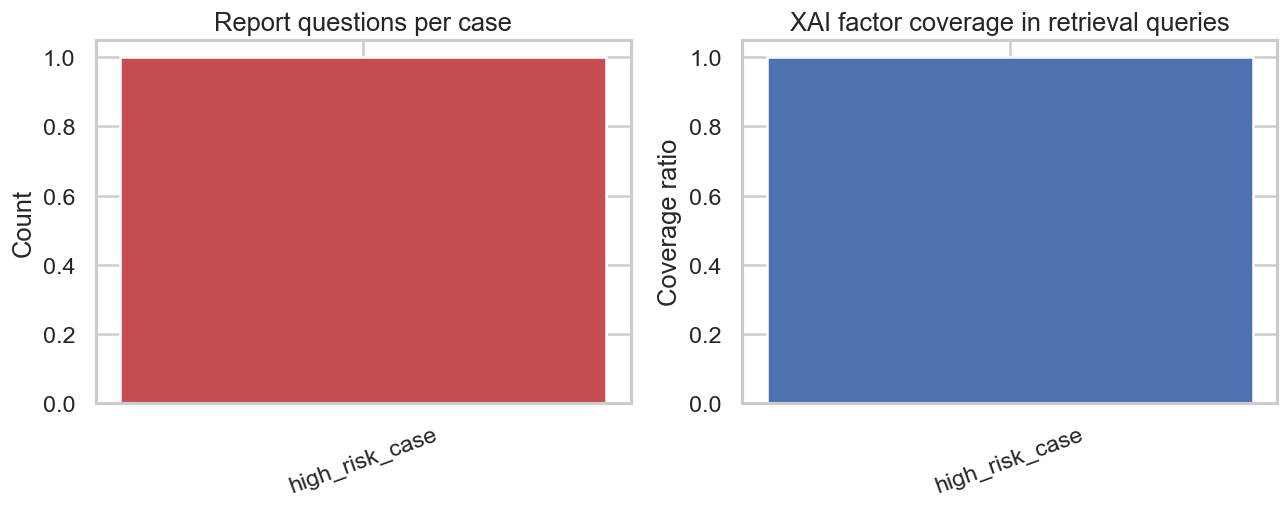

In [ ]:
def load_jsonl(path: Path) -> list[dict]:
    if not path.exists():
        return []
    return [json.loads(l) for l in path.read_text(encoding="utf-8").splitlines() if l.strip()]


def latest_by_case(records: list[dict], key="case_id") -> dict[str, dict]:
    out = {}
    for r in records:
        cid = r.get(key)
        if cid:
            out[cid] = r
    return out


plan_dir = cfg_path("results_dir") / "query_plans"
plans = []
for p in sorted(plan_dir.glob("*.json")):
    plans.append(json.loads(p.read_text(encoding="utf-8")))
if not plans:
    plans = load_jsonl(cfg_path("results_dir") / "query_plans.jsonl")

from controlled_agentic_xai_rag.inputs.loader import get_xai_card

qp_rows = []
for plan in plans:
    cid = plan.get("case_id", "")
    try:
        card = get_xai_card(cid)
    except Exception:
        card = {"top_positive_factors": []}
    xai_feats = {f.get("feature", "") for f in card.get("top_positive_factors", []) if f.get("feature")}
    rq = plan.get("retrieval_queries") or []
    covered = {q.get("xai_factor_ref") for q in rq if q.get("xai_factor_ref")}
    questions = plan.get("report_questions") or plan.get("internal_questions") or []
    qp_rows.append({
        "case_id": cid,
        "n_report_questions": len(questions),
        "n_retrieval_queries": len(rq),
        "xai_factor_coverage": len(covered & xai_feats) / max(len(xai_feats), 1),
        "n_xai_factors_in_card": len(xai_feats),
        "n_xai_factors_covered": len(covered & xai_feats),
        "has_risk_communication_slot": any(q.get("slot_type") == "risk_communication" for q in rq),
        "has_safety_slot": any("safety" in str(q.get("slot_type", "")) for q in rq),
    })

qp_df = pd.DataFrame(qp_rows)
display(qp_df.round(3))
qp_df.to_csv(OUT_DIR / "table4_query_planning.csv", index=False)

if not qp_df.empty:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    axes[0].bar(qp_df["case_id"], qp_df["n_report_questions"], color="#C44E52")
    axes[0].set_title("Report questions per case")
    axes[0].set_ylabel("Count")
    axes[0].tick_params(axis="x", rotation=20)
    axes[1].bar(qp_df["case_id"], qp_df["xai_factor_coverage"], color="#4C72B0")
    axes[1].set_ylim(0, 1.05)
    axes[1].set_title("XAI factor coverage in retrieval queries")
    axes[1].set_ylabel("Coverage ratio")
    axes[1].tick_params(axis="x", rotation=20)
    plt.tight_layout()
    savefig("fig6_query_planning_metrics.png")
    plt.show()

---
## 5. End-to-end report quality (offline evaluation)

Evaluates the **latest saved report per case** on schema validity, safety rules, XAI alignment, question coverage, and forbidden-claim violations.

,case_id,schema_valid,safety_pass,xai_alignment_pass,n_citations,question_coverage,n_report_questions,safety_status,has_disclaimer,narrative_chars
0,high_risk_case,True,True,True,0,0.0,1,draft_unvalidated,True,369
1,low_risk_case,True,True,True,8,NaN,0,accepted,True,896


,check,pass_rate,pass_rate_pct
0,schema_valid,1.0,100.0
1,safety_pass,1.0,100.0
2,xai_alignment_pass,1.0,100.0
3,has_disclaimer,1.0,100.0


Saved: c:\Users\MossabBatal\Desktop\psychology_mas\controlled_agentic_xai_rag\figures\paper\fig7_report_quality.png


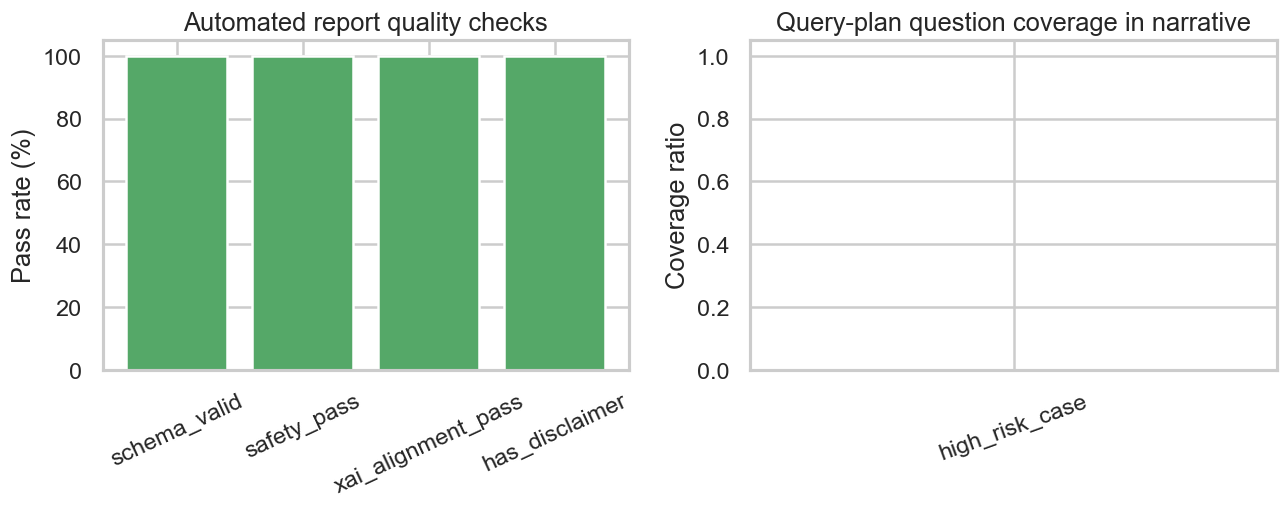

In [ ]:
if RUN_PIPELINE:
    from controlled_agentic_xai_rag.pipeline import PipelineOptions, run_case

    for cid in ["high_risk_case", "low_risk_case", "borderline_risk_case"]:
        print(f"Running pipeline: {cid}")
        run_case(cid, PipelineOptions(live_prediction=True))


def question_coverage(report: dict, plan: dict) -> float:
    questions = plan.get("report_questions") or plan.get("internal_questions") or []
    if not questions:
        return float("nan")
    text = report_text(report).lower()
    hit = 0
    for q in questions:
        tokens = [t for t in re.findall(r"[a-z]{4,}", str(q).lower()) if t not in {"what", "how", "does", "should", "with", "this", "that", "from", "about"}]
        if not tokens:
            continue
        if sum(1 for t in tokens[:6] if t in text) >= min(2, len(tokens[:6])):
            hit += 1
    return hit / len(questions)


def forbidden_violations(report: dict, forbidden: str) -> int:
    if not forbidden or str(forbidden) == "nan":
        return 0
    text = report_text(report).lower()
    return sum(1 for phrase in str(forbidden).split(";") if phrase.strip().lower() in text)


reports = {k: v for k, v in latest_by_case(load_jsonl(cfg_path("results_dir") / "final_narratives.jsonl")).items() if k in PRESET_CASE_IDS}
plans_by_case = {p.get("case_id"): p for p in plans}

report_rows = []
for cid, report in reports.items():
    try:
        card = get_xai_card(cid)
    except Exception:
        card = {"top_positive_factors": [], "prediction_probability": 0.5}
    elevated = float(card.get("prediction_probability", 0)) >= float(cfg_get("pipeline", "risk_threshold", default=0.5))
    schema_ok, schema_err = validate(report, "screening_report.json")
    safety = check_safety_rules(report, elevated=elevated)
    xai = check_xai_alignment(report, card)
    plan = plans_by_case.get(cid, {})
    report_rows.append({
        "case_id": cid,
        "schema_valid": schema_ok,
        "safety_pass": safety["passed"],
        "xai_alignment_pass": xai["passed"],
        "n_citations": len(report.get("citations") or []),
        "question_coverage": question_coverage(report, plan),
        "n_report_questions": len(plan.get("report_questions") or []),
        "safety_status": report.get("safety_status", ""),
        "has_disclaimer": "not a clinical diagnosis" in report_text(report).lower(),
        "narrative_chars": len(report_text(report)),
    })

report_df = pd.DataFrame(report_rows)
display(report_df.round(3))
report_df.to_csv(OUT_DIR / "table5_report_quality.csv", index=False)

if not report_df.empty:
    pass_cols = ["schema_valid", "safety_pass", "xai_alignment_pass", "has_disclaimer"]
    pass_rates = report_df[pass_cols].mean().rename("pass_rate").reset_index().rename(columns={"index": "check"})
    pass_rates["pass_rate_pct"] = (pass_rates["pass_rate"] * 100).round(1)
    display(pass_rates)
    pass_rates.to_csv(OUT_DIR / "table5b_report_pass_rates.csv", index=False)

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    axes[0].bar(pass_rates["check"], pass_rates["pass_rate_pct"], color="#55A868")
    axes[0].set_ylim(0, 105)
    axes[0].set_ylabel("Pass rate (%)")
    axes[0].set_title("Automated report quality checks")
    axes[0].tick_params(axis="x", rotation=25)
    axes[1].bar(report_df["case_id"], report_df["question_coverage"], color="#8172B3")
    axes[1].set_ylim(0, 1.05)
    axes[1].set_title("Query-plan question coverage in narrative")
    axes[1].set_ylabel("Coverage ratio")
    axes[1].tick_params(axis="x", rotation=20)
    plt.tight_layout()
    savefig("fig7_report_quality.png")
    plt.show()

,support_status,count
0,fully_supported,25
1,partially_supported,7


Saved: c:\Users\MossabBatal\Desktop\psychology_mas\controlled_agentic_xai_rag\figures\paper\fig8_citation_faithfulness.png


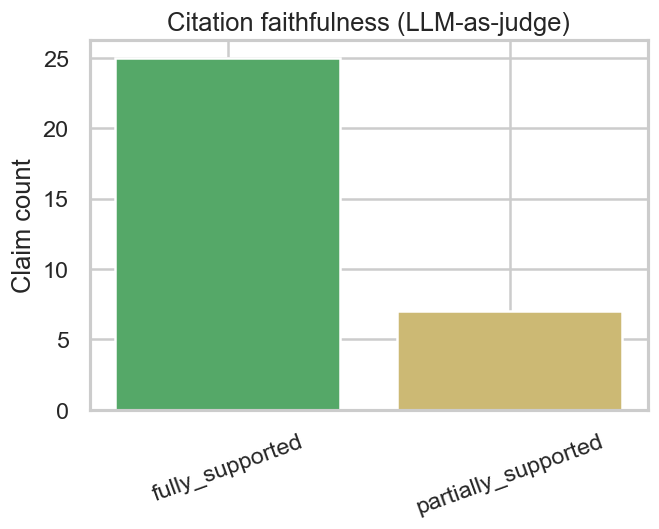

In [ ]:
claims_path = cfg_path("results_dir") / "claim_level_faithfulness.csv"
if claims_path.exists():
    claims = pd.read_csv(claims_path)
    faith_summary = claims.groupby("support_status").size().reset_index(name="count")
    display(faith_summary)
    faith_summary.to_csv(OUT_DIR / "table6_citation_faithfulness.csv", index=False)
    fig, ax = plt.subplots(figsize=(6, 4))
    colors = {"fully_supported": "#55A868", "partially_supported": "#CCB974", "unsupported": "#C44E52", "contradicted": "#8B0000"}
    ax.bar(faith_summary["support_status"], faith_summary["count"],
           color=[colors.get(s, "#999999") for s in faith_summary["support_status"]])
    ax.set_title("Citation faithfulness (LLM-as-judge)")
    ax.set_ylabel("Claim count")
    ax.tick_params(axis="x", rotation=20)
    savefig("fig8_citation_faithfulness.png")
    plt.show()
else:
    print("No claim_level_faithfulness.csv — run citation checker on saved reports for this figure.")

---
## 6. Master results table (for paper Table X)

In [ ]:
master = []
if pred_metrics.get("auc") is not None and not (isinstance(pred_metrics.get("auc"), float) and np.isnan(pred_metrics["auc"])):
    master.append({"component": "Prediction (CatBoost)", "metric": "AUC", "value": round(float(pred_metrics["auc"]), 4)})
    master.append({"component": "Prediction (CatBoost)", "metric": "F1", "value": round(float(pred_metrics["f1"]), 4)})
master.append({"component": "Knowledge base", "metric": "Documents", "value": kb_stats["n_documents"]})
master.append({"component": "Knowledge base", "metric": "Chunks", "value": kb_stats["n_chunks"]})

if not retrieval_detail.empty:
    for _, row in retrieval_summary_flat.iterrows():
        ret = row["retriever"]
        for m in METRIC_COLS:
            master.append({"component": f"Retrieval ({ret})", "metric": m, "value": row[m]})

if not qp_df.empty:
    master.append({"component": "Query planning", "metric": "Mean report questions", "value": round(qp_df["n_report_questions"].mean(), 2)})
    master.append({"component": "Query planning", "metric": "Mean XAI coverage", "value": round(qp_df["xai_factor_coverage"].mean(), 3)})

if not report_df.empty:
    master.append({"component": "Report quality", "metric": "Safety pass rate", "value": round(report_df["safety_pass"].mean(), 3)})
    master.append({"component": "Report quality", "metric": "XAI alignment pass rate", "value": round(report_df["xai_alignment_pass"].mean(), 3)})
    master.append({"component": "Report quality", "metric": "Question coverage", "value": round(report_df["question_coverage"].mean(), 3)})
    master.append({"component": "Report quality", "metric": "Mean citations", "value": round(report_df["n_citations"].mean(), 2)})

master_df = pd.DataFrame(master)
display(master_df)
master_df.to_csv(OUT_DIR / "table_master_results.csv", index=False)

try:
    latex = master_df.to_latex(index=False, float_format="%.3f", caption="System evaluation summary.", label="tab:system_eval")
    (OUT_DIR / "table_master_results.tex").write_text(latex, encoding="utf-8")
    print(f"LaTeX table: {OUT_DIR / 'table_master_results.tex'}")
except Exception as exc:
    print(f"LaTeX export skipped: {exc}")

Markdown(f"""
### Key numbers for the paper

- **Corpus:** {kb_stats['n_documents']} PDFs, {kb_stats['n_chunks']} chunks
- **Retrieval benchmark:** {len(bench)} questions (relaxed gold-chunk matching)
- **Cases evaluated:** {len(report_df) if not report_df.empty else 0} pipeline reports
- **Figures saved to:** `{FIG_DIR}`
- **Tables saved to:** `{OUT_DIR}`

**Suggested manuscript placement:** Fig 0 → Methods; Figs 1–2 → Dataset/Model; Figs 3–5 → Retrieval Results; Figs 6–8 → Agentic pipeline Results.
""")

,component,metric,value
0,Prediction (CatBoost),AUC,0.8520
1,Prediction (CatBoost),F1,0.7524
2,Knowledge base,Documents,44.0000
3,Knowledge base,Chunks,5740.0000
4,Retrieval (bm25),precision@5,0.0320
5,Retrieval (bm25),recall@5,0.0045
6,Retrieval (bm25),recall@10,0.0097
7,Retrieval (bm25),hit@5,0.1400
8,Retrieval (bm25),hit@10,0.2900
9,Retrieval (bm25),mrr,0.0919


LaTeX table: c:\Users\MossabBatal\Desktop\psychology_mas\controlled_agentic_xai_rag\paper_outputs\evaluation\table_master_results.tex



### Key numbers for the paper

- **Corpus:** 44 PDFs, 5740 chunks
- **Retrieval benchmark:** 100 questions (relaxed gold-chunk matching)
- **Cases evaluated:** 2 pipeline reports
- **Figures saved to:** `c:\Users\MossabBatal\Desktop\psychology_mas\controlled_agentic_xai_rag\figures\paper`
- **Tables saved to:** `c:\Users\MossabBatal\Desktop\psychology_mas\controlled_agentic_xai_rag\paper_outputs\evaluation`

**Suggested manuscript placement:** Fig 0 → Methods; Figs 1–2 → Dataset/Model; Figs 3–5 → Retrieval Results; Figs 6–8 → Agentic pipeline Results.
